# Coding session

In [3]:
from pathlib import Path
import importlib.util

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
from ipywidgets import Checkbox, Dropdown, FloatSlider, IntSlider, fixed, interact, interactive
from IPython.display import display


DATA = Path("data")                   
PID = "UPENN-GBM-00134_11" 
CASE = DATA / PID
MODS = ["T1", "T1GD", "T2", "FLAIR"]   

plt.rcParams["figure.dpi"] = 100
assert CASE.exists(), "Start Jupyter inside the session/ folder so that data/ is next to this notebook."

for f in sorted(CASE.iterdir()):
    print(f"{f.name:52s} {f.stat().st_size / 1e6:5.1f} MB")


UPENN-GBM-00134_11_FLAIR.nii.gz                        2.3 MB
UPENN-GBM-00134_11_FLAIR_unstripped.nii.gz             7.1 MB
UPENN-GBM-00134_11_T1.nii.gz                           2.4 MB
UPENN-GBM-00134_11_T1GD.nii.gz                         2.4 MB
UPENN-GBM-00134_11_T1GD_unstripped.nii.gz              8.6 MB
UPENN-GBM-00134_11_T1_unstripped.nii.gz                8.0 MB
UPENN-GBM-00134_11_T2.nii.gz                           2.5 MB
UPENN-GBM-00134_11_T2_unstripped.nii.gz                7.8 MB
UPENN-GBM-00134_11_automated_approx_segm.nii.gz        0.0 MB
UPENN-GBM-00134_11_segm.nii.gz                         0.0 MB



## 1. Intro to NIfTI and DICOM
### 1.1 Nifti


In [4]:
img = nib.load(CASE / f"{PID}_T1.nii.gz") 
t1 = np.asanyarray(img.dataobj) 

print("array shape      :", t1.shape, " dtype:", t1.dtype)
print("voxel size (mm)  :", tuple(float(z) for z in img.header.get_zooms()))
print("units            :", img.header.get_xyzt_units())
print("axis codes       :", nib.aff2axcodes(img.affine), "  (array axis i grows toward ...)")
print("intensity range  :", t1.min(), "...", t1.max(), f"  non-zero voxels: {(t1 > 0).mean():.0%}  (the rest is background)")
print("affine (voxel index -> mm):\n", np.round(img.affine, 2))

array shape      : (240, 240, 155)  dtype: int16
voxel size (mm)  : (1.0, 1.0, 1.0)
units            : ('mm', 'unknown')
axis codes       : ('L', 'P', 'S')   (array axis i grows toward ...)
intensity range  : 0 ... 825   non-zero voxels: 18%  (the rest is background)
affine (voxel index -> mm):
 [[ -1.   0.   0.  -0.]
 [  0.  -1.   0. 239.]
 [  0.   0.   1.   0.]
 [  0.   0.   0.   1.]]


In [5]:
print(img.header) 

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 0
dim             : [  3 240 240 155   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1. 1. 1. 1. 0. 0. 0. 0.]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b''
aux_file        : b''
qform_code      : scanner
sform_code      : unknown
quatern_b       : 0.0
quatern_c       : 0.0
quatern_d       : 1.0
qoffset_x       : -0.0
qoffset_y       : 239.0
qoffset_z       : 0.0
srow_x          : [0. 0. 0. 0.]
srow_y          : [0.

### 1.2 Anatomical planes

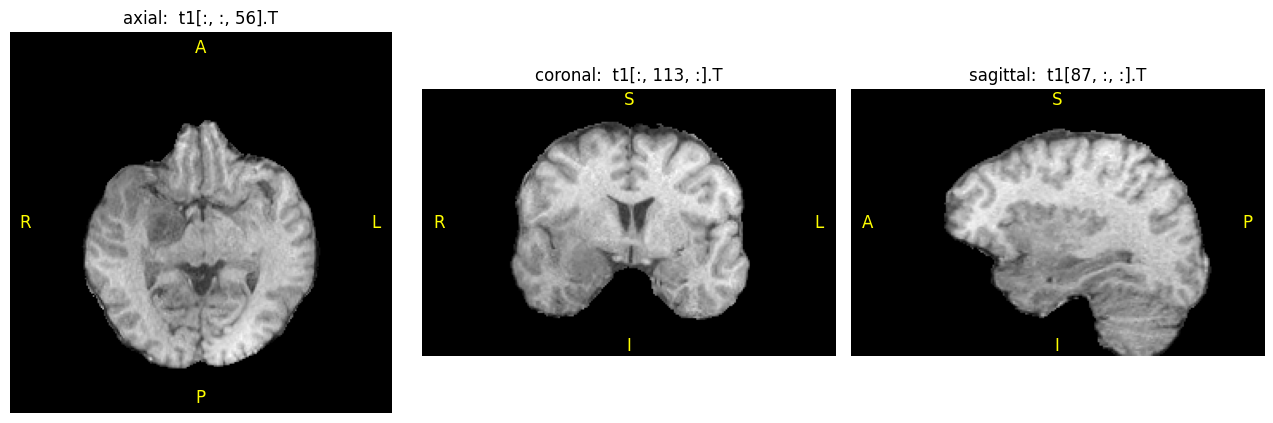

In [6]:
seg_man = np.asanyarray(nib.load(CASE / f"{PID}_segm.nii.gz").dataobj).astype(int)
cx, cy, cz = np.argwhere(seg_man > 0).mean(0).round().astype(int)   # tumour centre (voxel indices)
zx, zy, zz = img.header.get_zooms()[:3]


def side(ax, x, y, text):
    ax.text(x, y, text, transform=ax.transAxes, color="yellow", ha="center", va="center", fontsize=12)


fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ax[0].imshow(t1[:, :, cz].T, cmap="gray", aspect=zy / zx)                   # rows = y, columns = x
ax[0].set_title(f"axial:  t1[:, :, {cz}].T")
ax[1].imshow(t1[:, cy, :].T, cmap="gray", origin="lower", aspect=zz / zx)   # rows = z, columns = x
ax[1].set_title(f"coronal:  t1[:, {cy}, :].T")
ax[2].imshow(t1[cx, :, :].T, cmap="gray", origin="lower", aspect=zz / zy)   # rows = z, columns = y
ax[2].set_title(f"sagittal:  t1[{cx}, :, :].T")
for a, (top, bottom, left, right) in zip(ax, [("A", "P", "R", "L"), ("S", "I", "R", "L"), ("S", "I", "A", "P")]):
    side(a, 0.5, 0.96, top); side(a, 0.5, 0.04, bottom); side(a, 0.04, 0.5, left); side(a, 0.96, 0.5, right)
    a.axis("off")
plt.tight_layout()

### 1.3 Dicom

In [13]:
import pydicom
from pydicom.misc import is_dicom

DICOM_DIR = DATA / "dicom/I11671369"
dcm_files = [f for f in sorted(DICOM_DIR.rglob("*")) if f.is_file() and is_dicom(f)] if DICOM_DIR.exists() else []

print(f"{len(dcm_files)} DICOM file(s) found in {DICOM_DIR}")
ds = pydicom.dcmread(dcm_files[0])

def peek(ds, keys):
    for k in keys:
        print(f"{k:26s}", ds.get(k, "-"))


peek(ds, ["Modality", "Manufacturer", "StudyDate", "SeriesDescription", "Rows", "Columns", "PixelSpacing", "SliceThickness",
          "ImagePositionPatient", "ImageOrientationPatient", "RepetitionTime", "EchoTime", "BitsAllocated"])


208 DICOM file(s) found in data/dicom/I11671369
Modality                   MR
Manufacturer               Siemens Healthineers
StudyDate                  20260601
SeriesDescription          CLARiTI Accelerated Sagittal MPRAGE (MSV21)
Rows                       256
Columns                    240
PixelSpacing               [1, 1]
SliceThickness             1
ImagePositionPatient       [-43.4809, -141.37, 66.0198]
ImageOrientationPatient    [0, 1, 0, 0, 0, -1]
RepetitionTime             2300
EchoTime                   2.98
BitsAllocated              16


In [20]:
print(pydicom.dcmread(dcm_files[0]))

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 206
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: MR Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.840.113713.20.6207524112833389183815072385573167355488626369
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.826.0.1.3680043.8.498.1
(0002,0013) Implementation Version Name         SH: 'PYDICOM 2.4.2'
-------------------------------------------------
(0008,0000) Group Length                        UL: 852
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'M', 'NORM', 'DIS3D', 'MFSPLIT']
(0008,0013) Instance Creation Time              TM: '102517.397500'
(0008,0016) SOP Class UID                       UI: MR Image Storage
(

/home/hayoung/anaconda3/envs/py310/lib/python3.10/site-packages/pydicom/valuerep.py:440: UserWarning: The value length (20) exceeds the maximum length of 16 allowed for VR SH.
  warn_and_log(msg)


In [ ]:
import SimpleITK as sitk
reader = sitk.ImageSeriesReader()
dicom_names = reader.GetGDCMSeriesFileNames("/home/hayoung/code/test_seminar/data/dicom/I11671369")
reader.SetFileNames(dicom_names)

img_dicom = reader.Execute()
print("volume:", img_dicom.GetSize(), " voxel size (mm):", np.round(img_dicom.GetSpacing()))


img_np = sitk.GetArrayFromImage(img_dicom)


def view_mri(img_np):
    def show_slice(slice_idx):
        plt.figure(figsize=(7, 7))
        plt.imshow(img_np[:, slice_idx, : ], cmap='gray')
        plt.title(f'MRI Slice: {slice_idx}')
        plt.axis('off')
        plt.show()
    slider = IntSlider(value=img_np.shape[1] // 2, min=0, max=img_np.shape[1] - 1, step=1, description='Slice:', continuous_update=True)
    display(interactive(show_slice, slice_idx=slider))

view_mri(img_np)


volume: (240, 256, 208)  voxel size (mm): [1. 1. 1.]


interactive(children=(IntSlider(value=128, description='Slice:', max=255), Output()), _dom_classes=('widget-in…

In practice you often let a tool do this (and write NIfTI): `dcm2niix` (command line), SimpleITK, or MONAI's DICOM readers.

| task | tool |
|---|---|
| read / write NIfTI | nibabel |
| read DICOM headers and pixels | pydicom |
| DICOM series -> NIfTI | `dcm2niix`, SimpleITK |
| resampling, registration | SimpleITK, ANTs |
| deep learning pipelines (3D transforms, models, metrics) | MONAI |
| look at volumes interactively | 3D Slicer, ITK-SNAP |

### 1.4 Quick note: Skull-stripping 

same grid: True | non-zero voxels: stripped 18% | unstripped 70%
inside the brain mask the intensities are identical: True


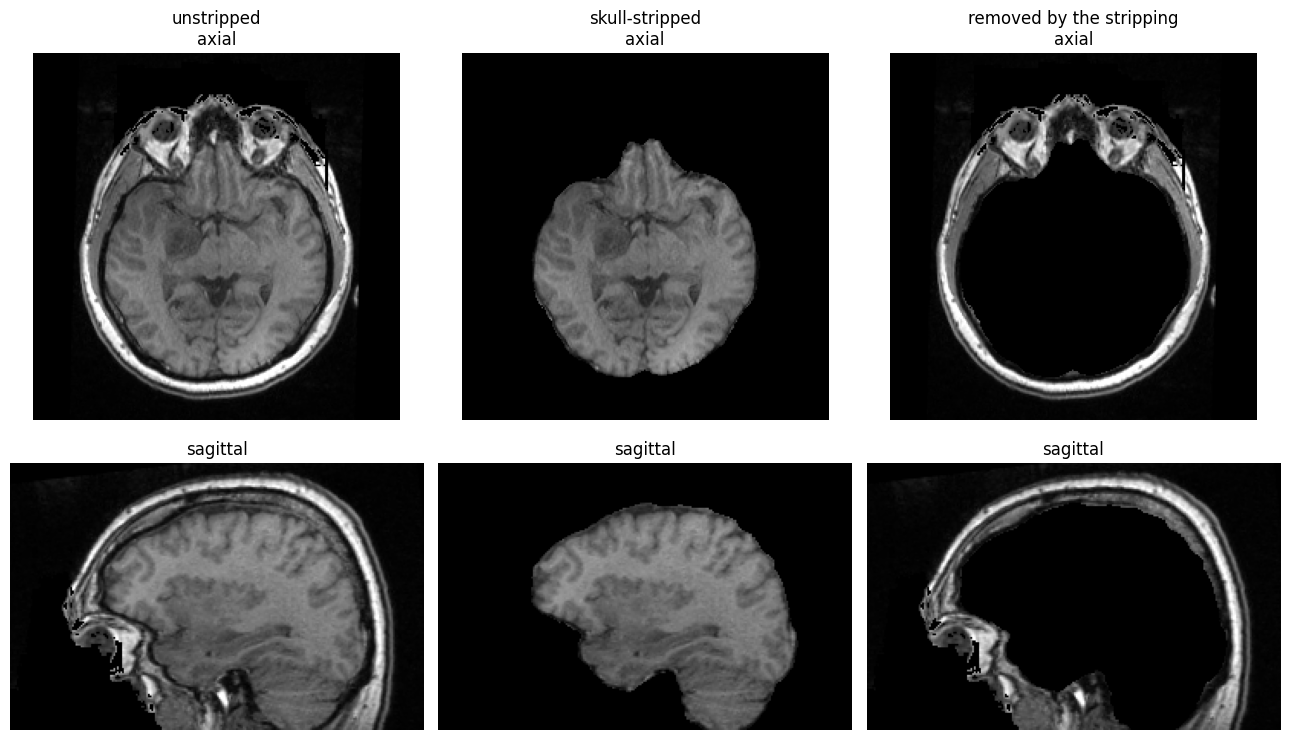

In [8]:
unstripped = np.asanyarray(nib.load(CASE / f"{PID}_T1_unstripped.nii.gz").dataobj)    
stripped = t1                                                                         
brain_mask = stripped > 0
removed = np.where(brain_mask, 0, unstripped)                                         

print("same grid:", stripped.shape == unstripped.shape, "| non-zero voxels: stripped", f"{brain_mask.mean():.0%}", "| unstripped", f"{(unstripped > 0).mean():.0%}")
print("inside the brain mask the intensities are identical:", bool((stripped[brain_mask] == unstripped[brain_mask]).all()))

vmax = np.percentile(unstripped, 99.5)                                                
fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for col, (title, v) in enumerate([("unstripped", unstripped), ("skull-stripped", stripped), ("removed by the stripping", removed)]):
    ax[0, col].imshow(v[:, :, cz].T, cmap="gray", vmin=0, vmax=vmax)
    ax[0, col].set_title(f"{title}\naxial")
    ax[1, col].imshow(v[cx, :, :].T, cmap="gray", vmin=0, vmax=vmax, origin="lower")
    ax[1, col].set_title("sagittal")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()

---
## 2. The four MRI modalities

### 2.1 T1, T1 Gd, T2, FLAIR
The same brain is scanned with several MRI sequences. Each one is sensitive to different tissue properties, so each shows the tumour differently:

| file | name | what it is good at |
|---|---|---|
| `T1` | T1-weighted | fluid is dark; anatomy; healthy structure, tumour is often dark |
| `T1GD` | T1 after gadolinium contrast (T1c) | active tumour: the contrast agent leaks out of damaged vessels and lights up the enhancing rim |
| `T2` | T2-weighted | fluid is bright: edema (swelling) and cysts |
| `FLAIR` | T2 with the fluid signal suppressed | edema stays bright, but normal fluid (ventricles) turns dark, so the swelling around the tumour stands out |

In [9]:
vols = {m: np.asanyarray(nib.load(CASE / f"{PID}_{m}.nii.gz").dataobj) for m in MODS}
assert len({v.shape for v in vols.values()}) == 1, "modalities must share one grid"
D = vols["T1"].shape[2]

rows = []
for m, v in vols.items():
    b = v[v > 0]
    rows.append({"modality": m, "dtype": str(v.dtype), "min": v.min(), "max": v.max(), "mean (brain)": round(float(b.mean()), 1),
                 "99.5th pct (brain)": round(float(np.percentile(b, 99.5)), 1), "brain voxels": f"{(v > 0).mean():.0%}"})
pd.DataFrame(rows).set_index("modality")

,dtype,min,max,mean (brain),99.5th pct (brain),brain voxels
modality,,,,,,
T1,int16,0,825,471.0,705.0,18%
T1GD,int16,0,3056,587.1,1782.0,18%
T2,int16,0,2694,640.3,1981.0,18%
FLAIR,int16,0,1082,229.7,485.0,18%


In [10]:
brain = np.any([v > 0 for v in vols.values()], axis=0)
xs, ys = np.flatnonzero(brain.any(axis=(1, 2))), np.flatnonzero(brain.any(axis=(0, 2)))
CROP = (slice(xs[0], xs[-1] + 1), slice(ys[0], ys[-1] + 1))


def plane(vol, z):
    """Axial slice z, cropped to the brain, as an upright image (rows = y, columns = x)."""
    return vol[CROP[0], CROP[1], z].T


NORMED = {} 


def show_modalities(z=cz, mode="raw"):
    data = vols if mode == "raw" else NORMED[mode]
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
    for a, m in zip(ax, MODS):
        v = data[m]
        lo, hi = {"raw": (v.min(), v.max()), "min-max [0, 1]": (0, 1), "z-score": (-3, 3)}[mode]
        im = a.imshow(plane(v, z), cmap="gray", vmin=lo, vmax=hi)
        a.set_title(f"{m}\nvolume range [{v.min():.3g}, {v.max():.3g}]", fontsize=10)
        a.axis("off")
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.02)
    fig.suptitle(f"axial slice z = {z}   ({mode})", y=1.0)
    plt.tight_layout()
    plt.show()


interact(show_modalities, z=IntSlider(min=0, max=D - 1, value=cz, description="slice z"), mode=fixed("raw"));

interactive(children=(IntSlider(value=56, description='slice z', max=154), Output()), _dom_classes=('widget-in…

### 2.2 Intensity

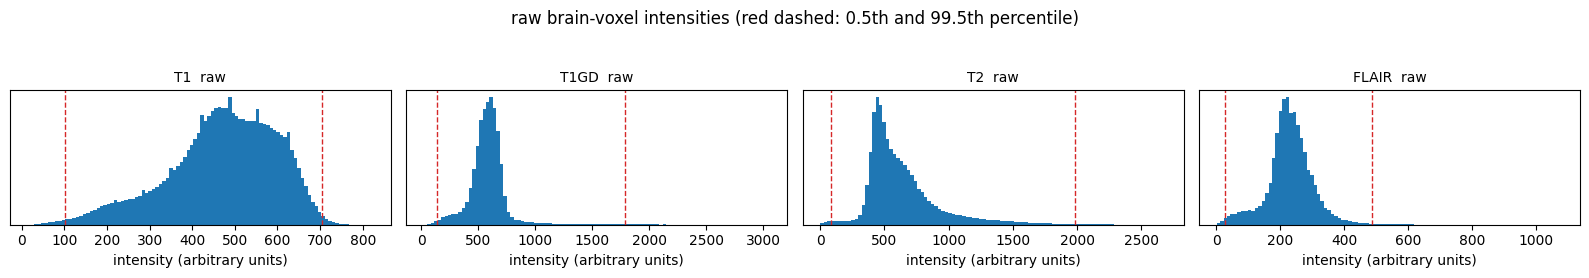

In [11]:
def hist_row(axes, data, title_suffix, lines=False):
    for a, m in zip(axes, MODS):
        v = data[m]
        vb = v[vols[m] > 0]
        a.hist(vb, bins=100, color="tab:blue")
        if lines:
            for p in np.percentile(vb, [0.5, 99.5]):
                a.axvline(p, color="tab:red", ls="--", lw=1)
        a.set_title(f"{m}  {title_suffix}", fontsize=10)
        a.set_yticks([])


fig, ax = plt.subplots(1, 4, figsize=(16, 2.6))
hist_row(ax, vols, "raw", lines=True)
for a in ax:
    a.set_xlabel("intensity (arbitrary units)")
fig.suptitle("raw brain-voxel intensities (red dashed: 0.5th and 99.5th percentile)", y=1.05)
plt.tight_layout()

### 2.3 How MRI is normally normalised

1. **Per volume and per modality**: never one global scale, because MRI units are not standardised across patients or scanners.
2. **Only brain voxels** (the non-zero mask) enter the statistics, so the large background does not distort them.
3. **Clip outliers**, e.g. at the 0.5th and 99.5th percentile, so a few very bright voxels do not decide the scale.
4. **Rescale**, either
   - *min-max* to [0, 1] after clipping, or
   - *z-score*: subtract the brain mean, divide by the brain standard deviation (the default of nnU-Net and many BraTS pipelines).
5. Keep the background at 0.

Not shown here: bias-field correction (N4) and histogram matching. UPenn-GBM already comes registered, resampled and skull-stripped.

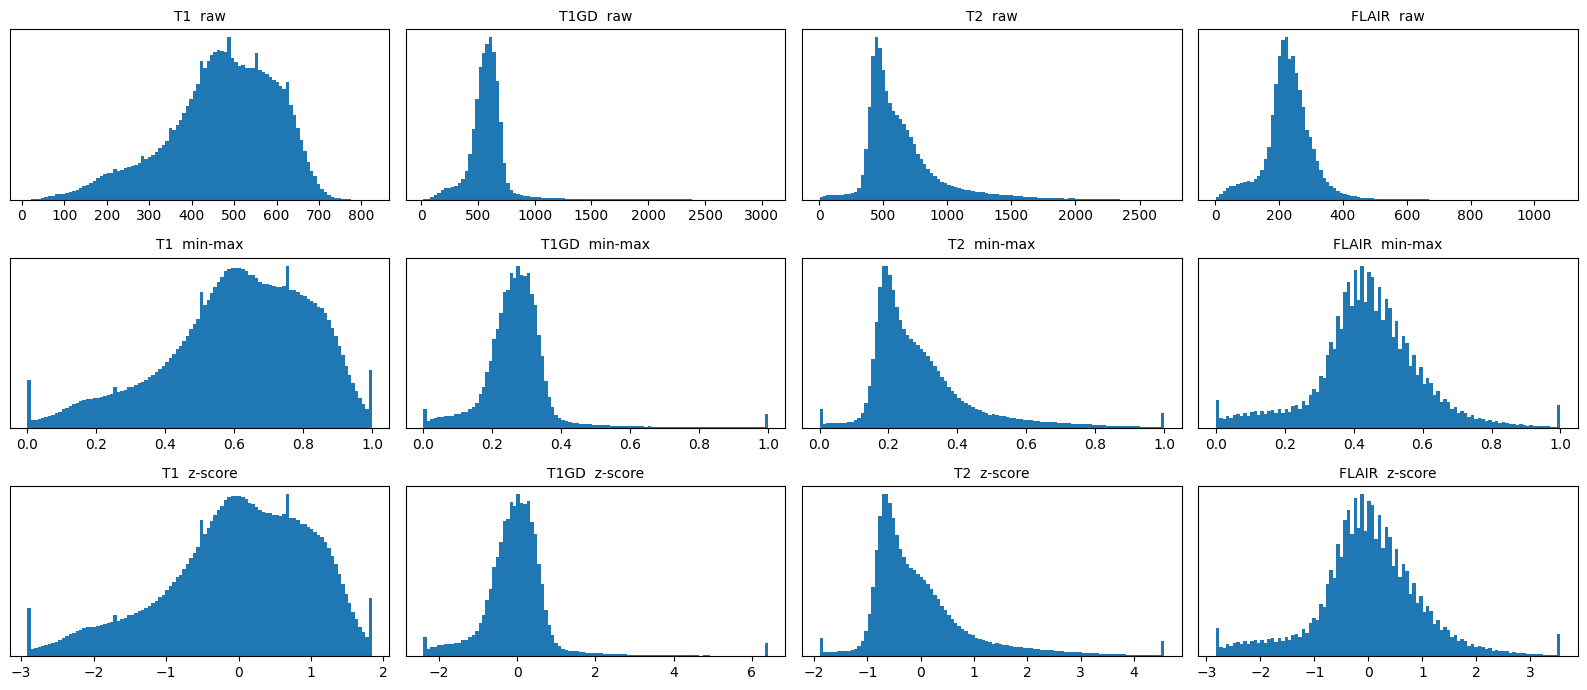

In [12]:
def normalize_minmax(v, pcts=(0.5, 99.5)):
    """Clip brain voxels at two percentiles and scale to [0, 1]. Background stays 0."""
    v = v.astype(np.float32)
    brain = v > 0
    lo, hi = np.percentile(v[brain], pcts)
    out = np.clip((v - lo) / (hi - lo), 0, 1)
    out[~brain] = 0
    return out


def normalize_zscore(v, pcts=(0.5, 99.5)):
    """Clip brain voxels at two percentiles, then subtract the brain mean and divide by the brain std. Background stays 0."""
    v = v.astype(np.float32)
    brain = v > 0
    lo, hi = np.percentile(v[brain], pcts)
    v = np.clip(v, lo, hi)
    out = (v - v[brain].mean()) / v[brain].std()
    out[~brain] = 0
    return out


NORMED["min-max [0, 1]"] = {m: normalize_minmax(v) for m, v in vols.items()}
NORMED["z-score"] = {m: normalize_zscore(v) for m, v in vols.items()}

fig, ax = plt.subplots(3, 4, figsize=(16, 7))
hist_row(ax[0], vols, "raw")
hist_row(ax[1], NORMED["min-max [0, 1]"], "min-max")
hist_row(ax[2], NORMED["z-score"], "z-score")
plt.tight_layout()

In [ ]:
interact(show_modalities, z=IntSlider(min=0, max=D - 1, value=cz, description="slice z"),
         mode=Dropdown(options=["raw", "min-max [0, 1]", "z-score"], value="min-max [0, 1]", description="intensities"));

interactive(children=(IntSlider(value=56, description='slice z', max=154), Dropdown(description='intensities',…

---
## 3. Segmentation

### 3.1 Segmentation labels

A segmentation is a label volume on the same grid as the images: one integer per voxel saying which tissue it belongs to.
UPenn-GBM uses the BraTS convention:

| label | name | what it is | where it is bright |
|---|---|---|---|
| 0 | background | healthy tissue (and outside the brain) | |
| 1 | necrotic core (NCR) | dead / non-enhancing tumour tissue in the middle | dark on T1GD |
| 2 | edema (ED) | swelling around the tumour, may contain infiltrating tumour cells | T2, FLAIR |
| 4 | enhancing tumour (ET) | the active, contrast-enhancing part | T1GD |

In [14]:
seg_auto = np.asanyarray(nib.load(CASE / f"{PID}_automated_approx_segm.nii.gz").dataobj).astype(int)
for name, s in [("manual", seg_man), ("automated", seg_auto)]:
    print(f"{name:10s} shape {s.shape}  labels present: {np.unique(s)}")
    
LABELS = {1: "necrotic core", 2: "edema", 4: "enhancing tumour"}
ml_per_voxel = np.prod(img.header.get_zooms()[:3]) / 1000          # voxel counts become volumes only through the voxel size
pd.DataFrame({"label name": ["background", *LABELS.values()],
              "voxels (manual)": [(seg_man == k).sum() for k in (0, *LABELS)],
              "volume mL (manual)": [round((seg_man == k).sum() * ml_per_voxel, 1) for k in (0, *LABELS)]},
             index=[0, *LABELS]).rename_axis("label")

manual     shape (240, 240, 155)  labels present: [0 1 2 4]
automated  shape (240, 240, 155)  labels present: [0 1 2 4]


,label name,voxels (manual),volume mL (manual)
label,,,
0,background,8890754,8890.8
1,necrotic core,5133,5.1
2,edema,29549,29.5
4,enhancing tumour,2564,2.6


In [15]:
from matplotlib.colors import ListedColormap

COLORS = {1: "blue", 2: "green", 4: "red"}
LUT = np.array([0, 1, 2, 0, 3])                                # label (0, 1, 2, 4) -> colour index (0, 1, 2, 3)
SEG_CMAP = ListedColormap([COLORS[1], COLORS[2], COLORS[4]])   # colour indices 1, 2, 3


def draw_overlay(ax, bg, seg, z, alpha=0.5, only=None):
    """Greyscale slice of `bg` with the labels of `seg` blended on top. `only` = show just this one label."""
    s = plane(seg, z)
    if only is not None:
        s = np.where(s == only, s, 0)
    ax.imshow(plane(bg, z), cmap="gray", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_equal(LUT[s], 0), cmap=SEG_CMAP, vmin=1, vmax=3, alpha=alpha, interpolation="nearest")
    ax.axis("off")
    return int((s > 0).sum())


BG = NORMED["min-max [0, 1]"]               # normalised images as background


def show_labels(z=cz, alpha=0.6, bg="T1"):
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
    for a, (title, only) in zip(ax, [("label 1: necrotic core", 1), ("label 2: edema", 2), ("label 4: enhancing tumour", 4), ("all labels", None)]):
        n = draw_overlay(a, BG[bg], seg_man, z, alpha, only)
        a.set_title(f"{title}\n{n} pixels on this slice", fontsize=10)
    fig.suptitle(f"manual segmentation on {bg}, axial slice z = {z}", y=1.0)
    plt.tight_layout()
    plt.show()


interact(show_labels, z=IntSlider(min=0, max=D - 1, value=cz, description="slice z"),
         alpha=FloatSlider(min=0, max=1, step=0.05, value=0.6, description="alpha"),
         bg=Dropdown(options=MODS, value="T1", description="background"));

interactive(children=(IntSlider(value=56, description='slice z', max=154), FloatSlider(value=0.6, description=…

Things to look for while scrolling: the enhancing tumour (red) is a thin rim, the necrotic core (blue) sits inside it, and the edema (green) is the largest region and
spreads around both. Switch the background to `T1GD` and `FLAIR` to see which modality supports which label.

### 3.2 Nested regions: WT, TC, ET

The three labels are not evaluated one by one. The standard evaluation (BraTS) uses three nested regions:

| region | made of | clinical meaning |
|---|---|---|
| WT whole tumour | labels 1 + 2 + 4 | everything abnormal |
| TC tumour core | labels 1 + 4 | what is usually resected / treated |
| ET enhancing tumour | label 4 | the active, contrast-enhancing part |

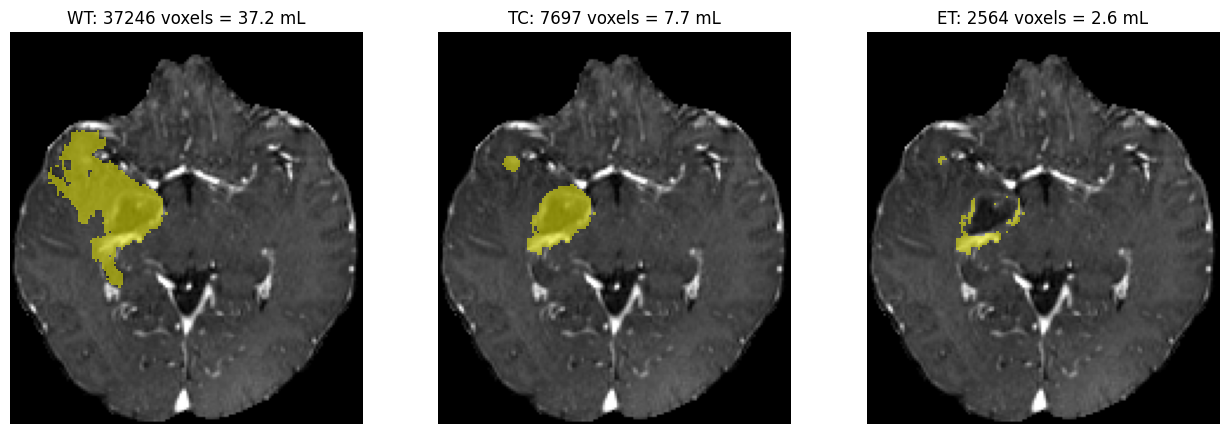

In [17]:
REGIONS = {"WT": lambda s: s > 0, "TC": lambda s: (s == 1) | (s == 4), "ET": lambda s: s == 4}  

fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a, (name, f) in zip(ax, REGIONS.items()):
    mask = f(seg_man)
    a.imshow(plane(BG["T1GD"], cz), cmap="gray", vmin=0, vmax=1)
    a.imshow(np.ma.masked_equal(plane(mask, cz).astype(int), 0), cmap=ListedColormap(["yellow"]), alpha=0.5, interpolation="nearest")
    a.set_title(f"{name}: {mask.sum()} voxels = {mask.sum() * ml_per_voxel:.1f} mL"); a.axis("off")
plt.tight_layout()

### 3.3 Manual vs automated segmentation

In [18]:
cmp = pd.DataFrame({"manual (voxels)": [(seg_man == k).sum() for k in LABELS],
                    "automated (voxels)": [(seg_auto == k).sum() for k in LABELS]}, index=list(LABELS.values()))
cmp["manual (mL)"] = (cmp["manual (voxels)"] * ml_per_voxel).round(1)
cmp["automated (mL)"] = (cmp["automated (voxels)"] * ml_per_voxel).round(1)
cmp

,manual (voxels),automated (voxels),manual (mL),automated (mL)
necrotic core,5133,3965,5.1,4.0
edema,29549,27132,29.5,27.1
enhancing tumour,2564,2583,2.6,2.6


In [19]:
z_dis = int(np.argmax((seg_man != seg_auto).sum(axis=(0, 1))))     # slice with the most differing voxels


def show_compare(z=z_dis, alpha=0.5, bg="T1", diff=False):
    n = 3 if diff else 2
    fig, ax = plt.subplots(1, n, figsize=(6.2 * n, 6.2))
    n_m = draw_overlay(ax[0], BG[bg], seg_man, z, alpha)
    n_a = draw_overlay(ax[1], BG[bg], seg_auto, z, alpha)
    ax[0].set_title(f"manual   ({n_m} tumour pixels)")
    ax[1].set_title(f"automated   ({n_a} tumour pixels)")
    if diff:
        d = (plane(seg_man, z) != plane(seg_auto, z)).astype(int)
        ax[2].imshow(plane(BG[bg], z), cmap="gray", vmin=0, vmax=1)
        ax[2].imshow(np.ma.masked_equal(d, 0), cmap=ListedColormap(["magenta"]), alpha=max(alpha, 0.6), interpolation="nearest")
        ax[2].set_title(f"labels differ   ({d.sum()} pixels)"); ax[2].axis("off")
    fig.suptitle(f"background {bg}, axial slice z = {z}   (blue: necrotic core, green: edema, red: enhancing tumour)", y=0.97)
    plt.tight_layout()
    plt.show()


interact(show_compare, z=IntSlider(min=0, max=D - 1, value=z_dis, description="slice z"),
         alpha=FloatSlider(min=0, max=1, step=0.05, value=0.5, description="alpha"),
         bg=Dropdown(options=MODS, value="T1", description="background"),
         diff=Checkbox(value=False, description="show disagreement"));

interactive(children=(IntSlider(value=59, description='slice z', max=154), FloatSlider(value=0.5, description=…

### 3.4 Same patient, but as 2D images

- 2D axial slices cut from Nifti volumnes, stored as PNG
- Class indices stored as 0 - 3, (label 4 → 3)
- Intensities in 8 bit (cliped at 0.5 th, 99.5th percentile, scaled to 1-255, backgroud 0)

In [21]:
from PIL import Image

DATA2D = DATA / "2D"
meta2d = pd.read_csv(DATA2D / "metadata.csv")
meta2d = meta2d[meta2d.patient_id == PID].sort_values("z").reset_index(drop=True)            

load_png = lambda path: np.array(Image.open(DATA2D / path))
imgs2d = {m: np.stack([load_png(p) for p in meta2d[f"path_{m}"]]) for m in MODS}            
seg2d = np.stack([load_png(p) for p in meta2d["path_seg"]])                              
n2d = len(meta2d)

print(f"{PID}: {n2d} slices per modality ({meta2d.has_tumor.sum()} with tumour, {(~meta2d.has_tumor).sum()} tumour-free), mask source: {meta2d.seg_source.iloc[0]}")
print("slice index z:", meta2d.z.tolist())
info = {m: {"slices": len(v), "image size": f"{v.shape[1]} x {v.shape[2]}", "dtype": str(v.dtype), "values": f"{v.min()} ... {v.max()}"} for m, v in imgs2d.items()}
info["seg"] = {"slices": len(seg2d), "image size": f"{seg2d.shape[1]} x {seg2d.shape[2]}", "dtype": str(seg2d.dtype), "values": str(np.unique(seg2d).tolist())}
display(pd.DataFrame(info).T)

UPENN-GBM-00134_11: 17 slices per modality (13 with tumour, 4 tumour-free), mask source: manual
slice index z: [5, 31, 35, 39, 43, 47, 51, 55, 59, 63, 67, 71, 75, 79, 84, 111, 130]


,slices,image size,dtype,values
T1,17,240 x 240,uint8,0 ... 255
T1GD,17,240 x 240,uint8,0 ... 255
T2,17,240 x 240,uint8,0 ... 255
FLAIR,17,240 x 240,uint8,0 ... 255
seg,17,240 x 240,uint8,"[0, 1, 2, 3]"


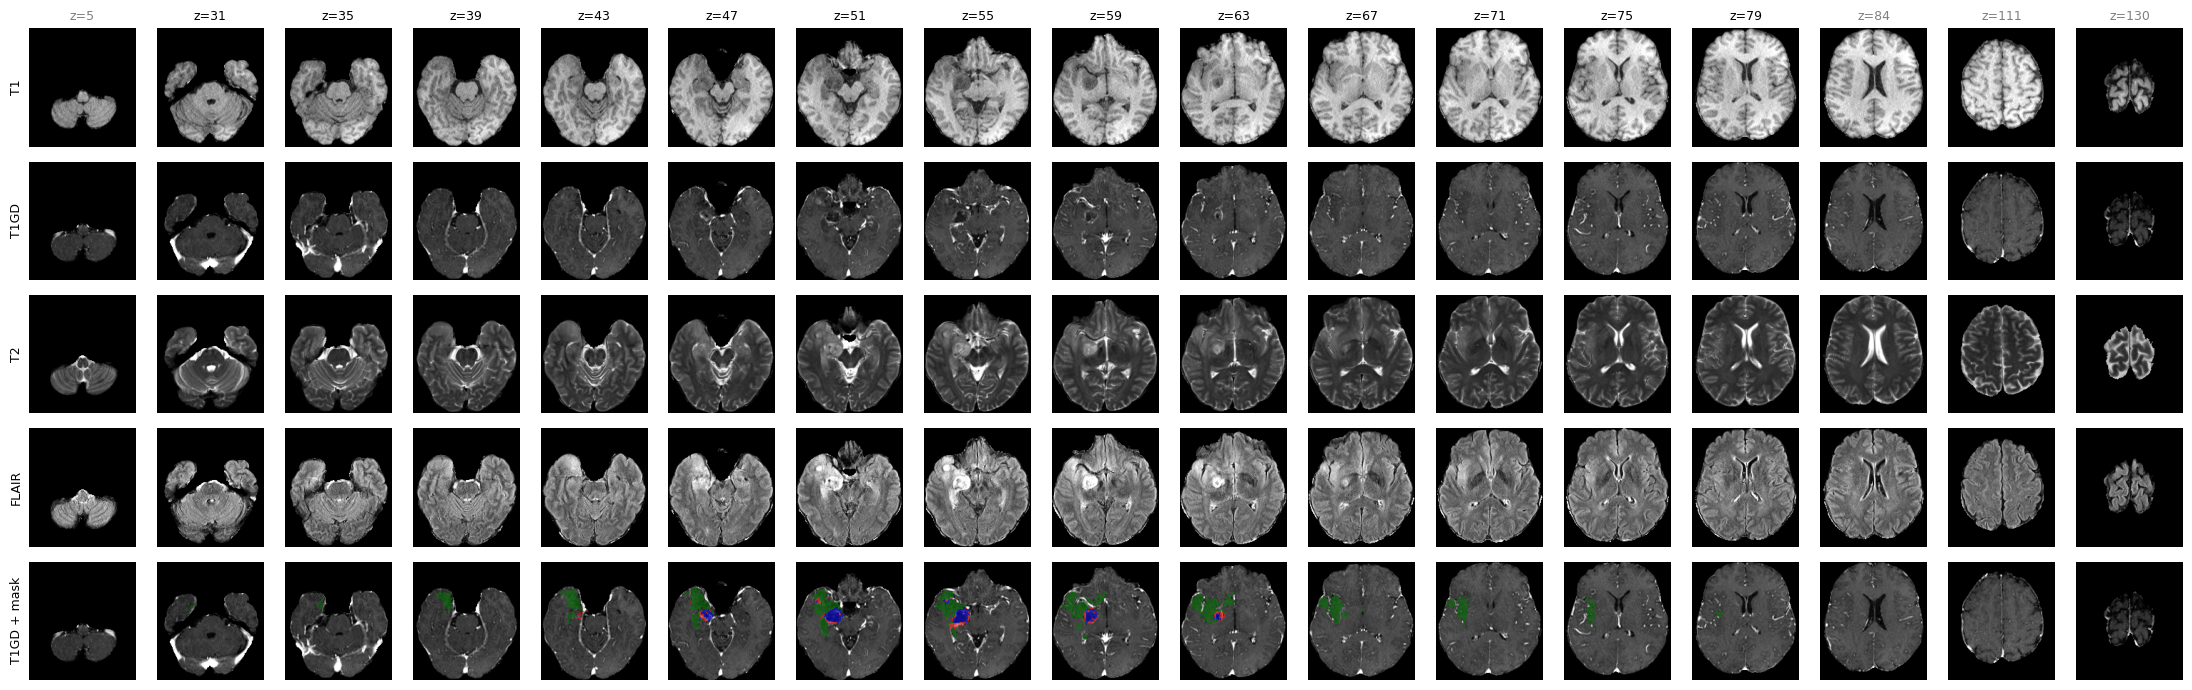

In [22]:
# all slices at once: one column per slice, one row per modality, last row = T1GD with the mask on top
brain2d = (imgs2d["T1"] > 0).any(axis=0)
rows, cols = np.flatnonzero(brain2d.any(axis=1)), np.flatnonzero(brain2d.any(axis=0))
box = (slice(rows[0], rows[-1] + 1), slice(cols[0], cols[-1] + 1))                            # crop to the brain, for display only


def overlay2d(ax, bg, seg, alpha=0.5):
    """Greyscale slice with the mask blended on top. Class 1 blue (necrotic), 2 green (oedema), 3 red (enhancing)."""
    ax.imshow(bg[box], cmap="gray", vmin=0, vmax=255)
    ax.imshow(np.ma.masked_equal(seg[box], 0), cmap=SEG_CMAP, vmin=1, vmax=3, alpha=alpha, interpolation="nearest")


fig, ax = plt.subplots(5, n2d, figsize=(1.3 * n2d, 7))
for j in range(n2d):
    for r, m in enumerate(MODS):
        ax[r, j].imshow(imgs2d[m][j][box], cmap="gray", vmin=0, vmax=255)
    overlay2d(ax[4, j], imgs2d["T1GD"][j], seg2d[j])
    ax[0, j].set_title(f"z={meta2d.z[j]}", fontsize=9, color="black" if meta2d.has_tumor[j] else "gray")      # gray = tumour-free slice
for r, name in enumerate([*MODS, "T1GD + mask"]):
    ax[r, 0].set_ylabel(name, fontsize=9)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
    for s in a.spines.values():
        s.set_visible(False)
plt.tight_layout()

In [23]:
def show_2d(k=int(meta2d.tumor_px.idxmax()), alpha=0.5, bg="T1GD"):
    fig, ax = plt.subplots(1, 5, figsize=(17, 3.8))
    for a, m in zip(ax, MODS):
        a.imshow(imgs2d[m][k][box], cmap="gray", vmin=0, vmax=255); a.set_title(m)
    overlay2d(ax[4], imgs2d[bg][k], seg2d[k], alpha); ax[4].set_title(f"{bg} + mask")
    for a in ax:
        a.axis("off")
    fig.suptitle(f"slice {k + 1} of {n2d}   z = {meta2d.z[k]}   tumour pixels: {meta2d.tumor_px[k]}", y=1.02)
    plt.tight_layout()
    plt.show()


interact(show_2d, k=IntSlider(min=0, max=n2d - 1, value=int(meta2d.tumor_px.idxmax()), description="slice #"),
         alpha=FloatSlider(min=0, max=1, step=0.05, value=0.5, description="alpha"),
         bg=Dropdown(options=MODS, value="T1GD", description="mask on"));

interactive(children=(IntSlider(value=6, description='slice #', max=16), FloatSlider(value=0.5, description='a…

---
## 4. Segmentation evaluation
### 4.1 Dice
A: Prediction
B: Ground truth



$$\mathrm{Dice}(A, B) = \frac{2\,|A \cap B|}{|A| + |B|} = \frac{2\,TP}{2\,TP + FP + FN}$$

- 1 = identical masks, 0 = no overlap at all. 

![image](data/dice.png)
img from https://marketplace.uipath.com/listings/the-dice-coefficient-string-matching-algorithm

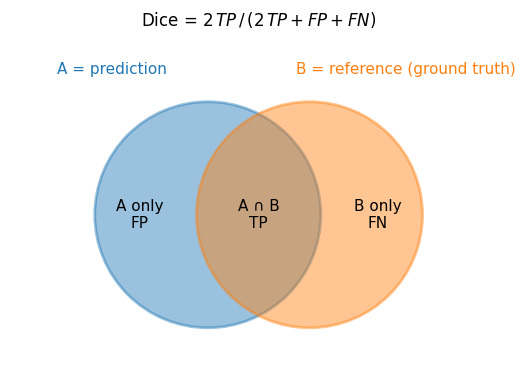

In [24]:
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.add_patch(Circle((-0.45, 0), 1, fc="tab:blue", alpha=0.45, ec="tab:blue", lw=2))
ax.add_patch(Circle((0.45, 0), 1, fc="tab:orange", alpha=0.45, ec="tab:orange", lw=2))
for x, t in [(-1.05, "A only\nFP"), (0, "A ∩ B\nTP"), (1.05, "B only\nFN")]:
    ax.text(x, 0, t, ha="center", va="center", fontsize=11)
ax.text(-1.3, 1.25, "A = prediction", color="tab:blue", ha="center", fontsize=11)
ax.text(1.3, 1.25, "B = reference (ground truth)", color="tab:orange", ha="center", fontsize=11)
ax.set_title(r"Dice = $2\,TP\,/\,(2\,TP + FP + FN)$")
ax.set_aspect("equal"); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-1.4, 1.6); ax.axis("off")
plt.tight_layout()

---
### 4.2 Dice calculation for manual segmentation (GT) VS automated segmentation (predicted)

In [25]:
def dice(a, b):
    """Dice = 2 |A and B| / (|A| + |B|). Two empty masks count as a perfect match."""
    a, b = a.astype(bool), b.astype(bool)
    den = a.sum() + b.sum()
    return 1.0 if den == 0 else 2.0 * (a & b).sum() / den


def overlap(pred, ref):
    """Voxel counts TP (in both), FP (only in the prediction) and FN (only in the reference)."""
    pred, ref = pred.astype(bool), ref.astype(bool)
    return int((pred & ref).sum()), int((pred & ~ref).sum()), int((~pred & ref).sum())


### 5.2 Automated vs manual segmentation of our patient


In [26]:
MASKS = {**REGIONS,
         "label 1 (necrotic)": lambda s: s == 1,
         "label 2 (edema)": lambda s: s == 2,
         "label 4 (enhancing)": lambda s: s == 4}


def dice_table(pred, ref, masks=MASKS):
    """Per mask: voxels in reference and prediction, TP / FP / FN, the errors relative to the reference size, and Dice."""
    rows = {}
    for name, f in masks.items():
        a, b = f(pred), f(ref)
        tp, fp, fn = overlap(a, b)
        size = max(int(b.sum()), 1)
        rows[name] = {"reference": int(b.sum()), "prediction": int(a.sum()), "TP": tp, "FP": fp, "FN": fn,
                      "FP / ref": fp / size, "FN / ref": fn / size, "Dice": dice(a, b)}
    return pd.DataFrame.from_dict(rows, orient="index")


dice_scores = dice_table(seg_auto, seg_man)           # prediction = automated, reference = manual
for name, r in dice_scores.iterrows():
    print(f"{name:20s} Dice = 2 x {r.TP:5.0f} / (2 x {r.TP:5.0f} + {r.FP:4.0f} + {r.FN:4.0f}) = {r.Dice:.3f}")
dice_scores.round({"FP / ref": 2, "FN / ref": 2, "Dice": 3})

WT                   Dice = 2 x 30828 / (2 x 30828 + 2852 + 6418) = 0.869
TC                   Dice = 2 x  6271 / (2 x  6271 +  277 + 1426) = 0.880
ET                   Dice = 2 x  1790 / (2 x  1790 +  793 +  774) = 0.696
label 1 (necrotic)   Dice = 2 x  3691 / (2 x  3691 +  274 + 1442) = 0.811
label 2 (edema)      Dice = 2 x 23372 / (2 x 23372 + 3760 + 6177) = 0.825
label 4 (enhancing)  Dice = 2 x  1790 / (2 x  1790 +  793 +  774) = 0.696


,reference,prediction,TP,FP,FN,FP / ref,FN / ref,Dice
WT,37246,33680,30828,2852,6418,0.08,0.17,0.869
TC,7697,6548,6271,277,1426,0.04,0.19,0.880
ET,2564,2583,1790,793,774,0.31,0.30,0.696
label 1 (necrotic),5133,3965,3691,274,1442,0.05,0.28,0.811
label 2 (edema),29549,27132,23372,3760,6177,0.13,0.21,0.825
label 4 (enhancing),2564,2583,1790,793,774,0.31,0.30,0.696


In [27]:
from matplotlib.patches import Patch

ERR_CMAP = ListedColormap(["white", "magenta", "cyan"])                        # 1 = TP (both), 2 = FN (only manual), 3 = FP (only automated)
z_et = int(np.argmax((MASKS["label 4 (enhancing)"](seg_auto) ^ MASKS["label 4 (enhancing)"](seg_man)).sum(axis=(0, 1))))


def show_errors(z=z_et, region="ET", bg="T1GD", alpha=0.7):
    f = MASKS[region]
    a, b = f(seg_auto[:, :, z]), f(seg_man[:, :, z])                            # prediction and reference on this slice
    tp, fp, fn = overlap(a, b)
    crop = lambda m: m[CROP[0], CROP[1]].T
    fig, ax = plt.subplots(1, 3, figsize=(17, 5.6))
    for k, (title, m) in enumerate([("manual (reference)", b), ("automated (prediction)", a)]):
        ax[k].imshow(plane(BG[bg], z), cmap="gray", vmin=0, vmax=1)
        ax[k].imshow(np.ma.masked_equal(crop(m).astype(int), 0), cmap=ListedColormap(["yellow"]), alpha=alpha, interpolation="nearest")
        ax[k].set_title(f"{title}: {region}, {int(m.sum())} pixels")
    err = np.where(a & b, 1, np.where(b, 2, np.where(a, 3, 0)))
    ax[2].imshow(plane(BG[bg], z), cmap="gray", vmin=0, vmax=1)
    ax[2].imshow(np.ma.masked_equal(crop(err), 0), cmap=ERR_CMAP, vmin=1, vmax=3, alpha=alpha, interpolation="nearest")
    ax[2].set_title(f"TP {tp}   FN {fn}   FP {fp}   ->   Dice of this slice {dice(a, b):.2f}")
    ax[2].legend(handles=[Patch(color="white", label="both (TP)"), Patch(color="magenta", label="only manual: missed (FN)"),
                          Patch(color="cyan", label="only automated: extra (FP)")], loc="lower center", fontsize=9, facecolor="dimgray", labelcolor="white")
    for a_ in ax:
        a_.axis("off")
    fig.suptitle(f"{region} on {bg}, axial slice z = {z}   |   Dice of the whole volume: {dice_scores.loc[region, 'Dice']:.3f}", y=1.0)
    plt.tight_layout()
    plt.show()


interact(show_errors, z=IntSlider(min=0, max=D - 1, value=z_et, description="slice z"),
         region=Dropdown(options=list(MASKS), value="ET", description="region / label"),
         bg=Dropdown(options=MODS, value="T1GD", description="background"),
         alpha=FloatSlider(min=0, max=1, step=0.05, value=0.7, description="alpha"));

interactive(children=(IntSlider(value=55, description='slice z', max=154), Dropdown(description='region / labe…

---
## 5. Training with complete vs incomplete data
### 5.1 data

In [28]:
import itertools
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

TRAIN_DIR, TEST_DIR, MODEL_DIR = Path("data_train"), Path("data_test"), Path("models")
MODEL_DIR.mkdir(exist_ok=True)

EPOCHS = 50   
BATCH = 16
LR = 3e-3
SEED = 0
TRAIN = True       

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| train patients:", len([p for p in TRAIN_DIR.iterdir() if p.is_dir()]),
      "| test patients:", len([p for p in TEST_DIR.iterdir() if p.is_dir()]))

device: cuda | train patients: 8 | test patients: 4


loaded in 19 s
train: 360 slices from 8 patients, x (360, 4, 120, 120), tumour pixels: 1.5%
test : 558 slices from 4 patients


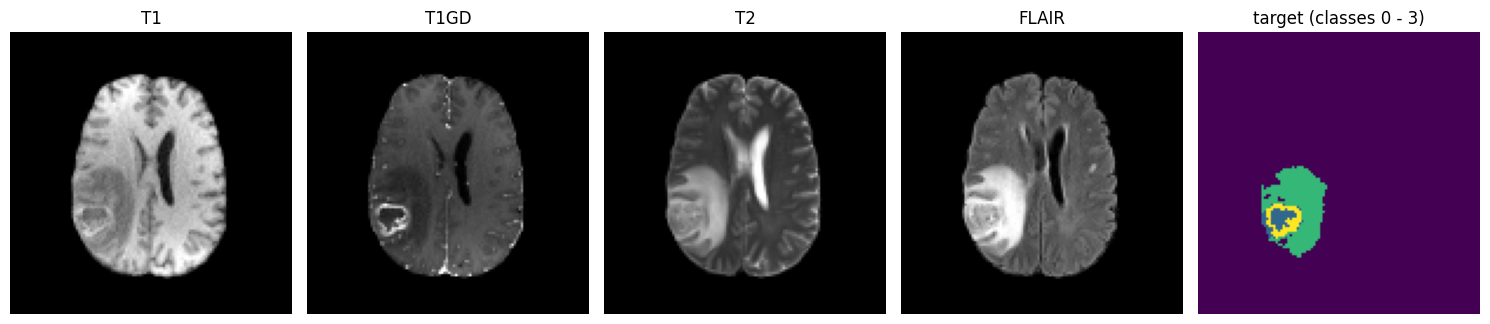

In [29]:
CLASS_OF_LABEL = np.array([0, 1, 2, 0, 3], np.uint8) 
LABEL_OF_CLASS = np.array([0, 1, 2, 4], np.uint8) 

def load_patient(folder):
    """One patient folder -> x (slices, 4, 120, 120) float32 in [0, 1] and y (slices, 120, 120) class indices."""
    pid = folder.name
    x = np.stack([normalize_minmax(np.asanyarray(nib.load(folder / f"{pid}_{m}.nii.gz").dataobj)) for m in MODS])   # (4, 240, 240, D)
    y = CLASS_OF_LABEL[np.asanyarray(nib.load(folder / f"{pid}_segm.nii.gz").dataobj).astype(int)]                  # (240, 240, D)
    n, h, w = x.shape[3], x.shape[1], x.shape[2]
    x = x.transpose(3, 0, 1, 2).reshape(n, 4, h // 2, 2, w // 2, 2).mean(axis=(3, 5))
    y = y.transpose(2, 0, 1)[:, ::2, ::2]
    return x.astype(np.float32), np.ascontiguousarray(y)


def load_split(root, train):
    X, Y, P = [], [], []
    for folder in sorted(p for p in root.iterdir() if p.is_dir()):
        x, y = load_patient(folder)
        has_brain, has_tumour = x.max(axis=(1, 2, 3)) > 0, (y > 0).any(axis=(1, 2))
        if train:
            keep = np.sort(np.concatenate([np.flatnonzero(has_tumour)[::2], np.flatnonzero(has_brain & ~has_tumour)[::6]]))
        else:
            keep = np.flatnonzero(has_brain)
        X.append(x[keep]); Y.append(y[keep]); P += [folder.name] * len(keep)
    return np.concatenate(X), np.concatenate(Y), np.array(P)


t0 = time.time()
Xtr, Ytr, Ptr = load_split(TRAIN_DIR, train=True)
Xte, Yte, Pte = load_split(TEST_DIR, train=False)
print(f"loaded in {time.time() - t0:.0f} s")
print(f"train: {len(Xtr)} slices from {len(np.unique(Ptr))} patients, x {Xtr.shape}, tumour pixels: {(Ytr > 0).mean():.1%}")
print(f"test : {len(Xte)} slices from {len(np.unique(Pte))} patients")

i = int(np.argmax((Ytr > 0).sum(axis=(1, 2))))
fig, ax = plt.subplots(1, 5, figsize=(15, 3.2))
for k, m in enumerate(MODS):
    ax[k].imshow(Xtr[i, k].T, cmap="gray", vmin=0, vmax=1); ax[k].set_title(m)
ax[4].imshow(Ytr[i].T, cmap="viridis", vmin=0, vmax=3); ax[4].set_title("target (classes 0 - 3)")
for a in ax:
    a.axis("off")
plt.tight_layout()

### 5.2 The model

A small 2D U-Net
Input: 4 channels (one per modality). Output: 4 channels (one score per class).

In [30]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )


class TinyUNet(nn.Module):
    """Small 2D U-Net. Input (B, 4, H, W) = T1, T1GD, T2, FLAIR; output (B, 4, H, W) class scores. H and W must be divisible by 8."""

    def __init__(self, in_ch=4, n_classes=4, base=8):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        self.enc1, self.enc2, self.enc3 = conv_block(in_ch, c1), conv_block(c1, c2), conv_block(c2, c3)
        self.bottom = conv_block(c3, c4)
        self.pool = nn.MaxPool2d(2)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), conv_block(c3 * 2, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), conv_block(c2 * 2, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), conv_block(c1 * 2, c1)
        self.head = nn.Conv2d(c1, n_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottom(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(b), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)


print(f"{sum(p.numel() for p in TinyUNet().parameters()) / 1e3:.0f}k parameters")

121k parameters


### 5.3 Training: complete vs incomplete

- The two trainings are identical (same seed, same initial weights, same loss, same data) except for one line:
- for the *incomplete* model, every training slice gets a random availability mask that sets some modalities to zero.

- loss: cross-entropy + Dice loss


In [31]:
def soft_dice_loss(logits, y):
    p = logits.softmax(1)
    t = F.one_hot(y, 4).permute(0, 3, 1, 2).float()
    inter, den = (p * t).sum((0, 2, 3)), p.sum((0, 2, 3)) + t.sum((0, 2, 3))
    return 1 - ((2 * inter + 1) / (den + 1))[1:].mean() 


def random_availability(batch, p=0.5):
    """(B, 4, 1, 1) mask of 0 / 1: each modality is kept with probability p, but never all four missing."""
    keep = torch.rand(batch, 4) < p
    while (empty := ~keep.any(1)).any():
        keep[empty] = torch.rand(int(empty.sum()), 4) < p
    return keep.float()[:, :, None, None]


def train_model(X, Y, incomplete, epochs=EPOCHS):
    torch.manual_seed(SEED)
    model = TinyUNet().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    X, Y = torch.from_numpy(X), torch.from_numpy(Y).long()
    history = []
    for epoch in range(epochs):
        model.train()
        order, total, n = torch.randperm(len(X)), 0.0, 0
        for s in range(0, len(order) - BATCH + 1, BATCH):
            idx = order[s:s + BATCH]
            xb, yb = X[idx], Y[idx]
            if incomplete:
                xb = xb * random_availability(len(xb))
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = F.cross_entropy(logits, yb) + soft_dice_loss(logits, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total, n = total + loss.item(), n + 1
        history.append(total / n)
        print(f"  epoch {epoch + 1:2d}/{epochs}  loss {history[-1]:.3f}", flush=True)
    return model, history


history = {}
if TRAIN:
    for name, incomplete in [("complete", False), ("incomplete", True)]:
        print(f"training the {name} model ...")
        t0 = time.time()
        model, history[name] = train_model(Xtr, Ytr, incomplete)
        torch.save(model.state_dict(), MODEL_DIR / f"unet_{name}.pt")
        print(f"  done in {time.time() - t0:.0f} s, saved to {MODEL_DIR / f'unet_{name}.pt'}")
else:
    print("TRAIN = False: using the checkpoints already in", MODEL_DIR)

training the complete model ...


/home/hayoung/anaconda3/envs/py310/lib/python3.10/site-packages/torch/cuda/__init__.py:484: UserWarning: Found GPU1 Quadro P2000 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.14.1+cu130 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/home/hayoung/anaconda3/envs/py310/lib/python3.10/site-packages/torch/cuda/__init__.py:602: UserWarning: 
Quadro P2000 with CUDA 

  epoch  1/50  loss 2.022
  epoch  2/50  loss 1.627
  epoch  3/50  loss 1.383
  epoch  4/50  loss 1.208
  epoch  5/50  loss 1.064
  epoch  6/50  loss 0.969
  epoch  7/50  loss 0.915
  epoch  8/50  loss 0.865
  epoch  9/50  loss 0.843
  epoch 10/50  loss 0.824
  epoch 11/50  loss 0.804
  epoch 12/50  loss 0.786
  epoch 13/50  loss 0.741
  epoch 14/50  loss 0.712
  epoch 15/50  loss 0.693
  epoch 16/50  loss 0.646
  epoch 17/50  loss 0.634
  epoch 18/50  loss 0.575
  epoch 19/50  loss 0.499
  epoch 20/50  loss 0.447
  epoch 21/50  loss 0.455
  epoch 22/50  loss 0.411
  epoch 23/50  loss 0.392
  epoch 24/50  loss 0.385
  epoch 25/50  loss 0.357
  epoch 26/50  loss 0.380
  epoch 27/50  loss 0.345
  epoch 28/50  loss 0.344
  epoch 29/50  loss 0.319
  epoch 30/50  loss 0.306
  epoch 31/50  loss 0.359
  epoch 32/50  loss 0.387
  epoch 33/50  loss 0.333
  epoch 34/50  loss 0.293
  epoch 35/50  loss 0.321
  epoch 36/50  loss 0.292
  epoch 37/50  loss 0.281
  epoch 38/50  loss 0.312
  epoch 39/5

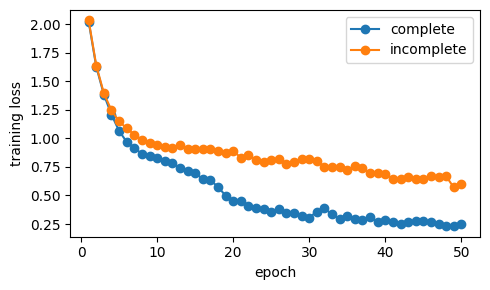

In [32]:
if history:
    plt.figure(figsize=(5, 3))
    for name, h in history.items():
        plt.plot(range(1, len(h) + 1), h, marker="o", label=name)
    plt.xlabel("epoch"); plt.ylabel("training loss"); plt.legend(); plt.tight_layout()

### 5.4 Evaluation


In [33]:
def load_model(path):
    model = TinyUNet().to(device)
    model.load_state_dict(torch.load(path, map_location=device))
    return model.eval()


models = {name: load_model(MODEL_DIR / f"unet_{name}.pt") for name in ("complete", "incomplete")}
print("loaded:", {name: f"{MODEL_DIR / f'unet_{name}.pt'}" for name in models})


@torch.no_grad()
def predict(model, X, available, batch=64):
    """BraTS label map (N, H, W) when only the modalities in `available` (indices 0..3) are present; missing ones are zeros."""
    keep = torch.zeros(1, 4, 1, 1, device=device)
    keep[0, list(available)] = 1
    out = [model(torch.from_numpy(X[s:s + batch]).to(device) * keep).argmax(1).cpu().numpy() for s in range(0, len(X), batch)]
    return LABEL_OF_CLASS[np.concatenate(out)]                      # class index -> BraTS label


def evaluate(pred, gt, ids):
    """Dice per patient (all slices of a patient pooled), then the mean over patients, for WT / TC / ET."""
    return {r: float(np.mean([dice(f(pred[ids == p]), f(gt[ids == p])) for p in np.unique(ids)])) for r, f in REGIONS.items()}


Yte_labels = LABEL_OF_CLASS[Yte]
combos = [c for n in range(1, 5) for c in itertools.combinations(range(4), n)]
rows = {}
for c in combos:
    for name, model in models.items():
        for region, v in evaluate(predict(model, Xte, c), Yte_labels, Pte).items():
            rows.setdefault("+".join(MODS[k] for k in c), {})[(name, region)] = v
results = pd.DataFrame(rows).T
results.columns = pd.MultiIndex.from_tuples(results.columns)
# results.round(2)

loaded: {'complete': 'models/unet_complete.pt', 'incomplete': 'models/unet_incomplete.pt'}


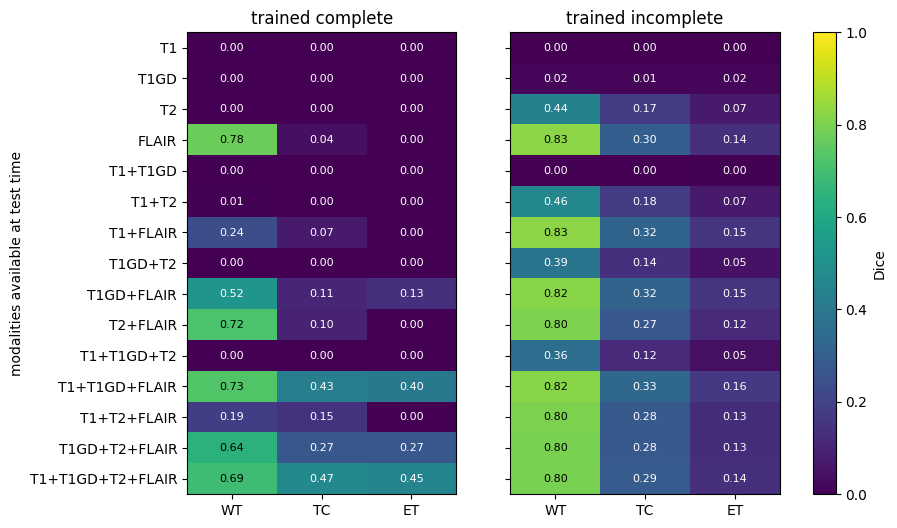

In [34]:
def heatmap(ax, df, title):
    im = ax.imshow(df.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns); ax.set_yticks(range(len(df)), df.index)
    for r in range(len(df)):
        for c in range(df.shape[1]):
            ax.text(c, r, f"{df.values[r, c]:.2f}", ha="center", va="center", color="white" if df.values[r, c] < 0.6 else "black", fontsize=8)
    ax.set_title(title)
    return im


fig, ax = plt.subplots(1, 2, figsize=(8.5, 6), sharey=True)
for a, name in zip(ax, models):
    im = heatmap(a, results[name], f"trained {name}")
fig.colorbar(im, ax=ax, label="Dice", fraction=0.05)
ax[0].set_ylabel("modalities available at test time")
plt.show()

,complete,incomplete
number of modalities available,,
1,0.07,0.17
2,0.11,0.28
3,0.26,0.36
4,0.54,0.41


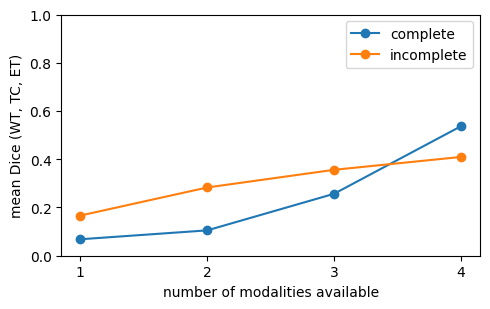

In [35]:
n_avail = pd.Series([len(c) for c in combos], index=["+".join(MODS[k] for k in c) for c in combos])
summary = pd.DataFrame({name: results[name].mean(axis=1).groupby(n_avail).mean() for name in models})     # mean over WT / TC / ET and over combinations
summary.index.name = "number of modalities available"

summary.plot(marker="o", figsize=(5, 3.2), ylim=(0, 1), xticks=[1, 2, 3, 4], ylabel="mean Dice (WT, TC, ET)")
plt.tight_layout()
summary.round(2)

1. **All four modalities** (last row of the table): which model is better when nothing is missing? Does training on incomplete data cost something?
2. **Missing modalities**: how fast does each model fall when sequences are removed? A model that never saw a zero channel in training can break down completely.
3. Which **region** (WT, TC, ET) suffers most when a sequence is missing, and which **sequence** is the most harmful to lose? 


---
**Data and citation.** UPenn-GBM data from TCIA, CC BY 4.0. Bakas, S., et al. (2021). *Multi-parametric magnetic resonance imaging (mpMRI) scans for de novo Glioblastoma (GBM) patients from the University of Pennsylvania Health System (UPENN-GBM)* [Dataset]. The Cancer Imaging Archive.